# Predicting Credit Card Default — Data Preprocessing & Initial Model Development
**Dataset:** Default of Credit Card Clients (Yeh & Lien, 2009), UCI Machine Learning Repository, ID 350 — 30,000 Taiwanese card holders, April–September 2005.

**Business question:** Using six months of billing and repayment history plus basic account attributes, can we flag which card holders are likely to default on next month's payment, early enough for a lender to intervene (payment plans, limit review, outreach)?

**Deliverable scope:** exploration, cleaning, feature engineering, and two baseline classifiers (Logistic Regression, Random Forest), with a first fairness check.

## 1. Setup and imports

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             f1_score, recall_score, precision_score, accuracy_score,
                             RocCurveDisplay, average_precision_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=160, bbox_inches="tight")
    plt.show()

## 2. Load the data
In Colab, the cell below pulls the dataset straight from UCI with `ucimlrepo`. If a local copy of `UCI_Credit_Card.csv` (Kaggle/UCI export) is present, that is used instead. Alternatively, upload it with `from google.colab import files; files.upload()`.

In [2]:
LOCAL_FILE = "data/UCI_Credit_Card.csv" if os.path.exists("data/UCI_Credit_Card.csv") else "UCI_Credit_Card.csv"

if os.path.exists(LOCAL_FILE):
    df_raw = pd.read_csv(LOCAL_FILE)
    df_raw = df_raw.rename(columns={"default.payment.next.month": "DEFAULT"})
else:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ucimlrepo"], check=True)
    from ucimlrepo import fetch_ucirepo
    repo = fetch_ucirepo(id=350)
    names = ["LIMIT_BAL","SEX","EDUCATION","MARRIAGE","AGE",
             "PAY_0","PAY_2","PAY_3","PAY_4","PAY_5","PAY_6",
             "BILL_AMT1","BILL_AMT2","BILL_AMT3","BILL_AMT4","BILL_AMT5","BILL_AMT6",
             "PAY_AMT1","PAY_AMT2","PAY_AMT3","PAY_AMT4","PAY_AMT5","PAY_AMT6"]
    X_ = repo.data.features.copy(); X_.columns = names
    df_raw = X_.assign(DEFAULT=repo.data.targets.iloc[:, 0].values)
    df_raw.insert(0, "ID", np.arange(1, len(df_raw) + 1))

print("Shape:", df_raw.shape)
df_raw.head()

Shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


## 3. Data exploration

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         30000 non-null  int64  
 1   LIMIT_BAL  30000 non-null  float64
 2   SEX        30000 non-null  int64  
 3   EDUCATION  30000 non-null  int64  
 4   MARRIAGE   30000 non-null  int64  
 5   AGE        30000 non-null  int64  
 6   PAY_0      30000 non-null  int64  
 7   PAY_2      30000 non-null  int64  
 8   PAY_3      30000 non-null  int64  
 9   PAY_4      30000 non-null  int64  
 10  PAY_5      30000 non-null  int64  
 11  PAY_6      30000 non-null  int64  
 12  BILL_AMT1  30000 non-null  float64
 13  BILL_AMT2  30000 non-null  float64
 14  BILL_AMT3  30000 non-null  float64
 15  BILL_AMT4  30000 non-null  float64
 16  BILL_AMT5  30000 non-null  float64
 17  BILL_AMT6  30000 non-null  float64
 18  PAY_AMT1   30000 non-null  float64
 19  PAY_AMT2   30000 non-null  float64
 20  PAY_AMT3   30000 

In [4]:
df_raw.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.5,8660.4,1.0,7500.8,15000.5,22500.2,30000.0
LIMIT_BAL,30000.0,167484.3,129747.7,10000.0,50000.0,140000.0,240000.0,1000000.0
SEX,30000.0,1.6,0.5,1.0,1.0,2.0,2.0,2.0
EDUCATION,30000.0,1.9,0.8,0.0,1.0,2.0,2.0,6.0
MARRIAGE,30000.0,1.6,0.5,0.0,1.0,2.0,2.0,3.0
AGE,30000.0,35.5,9.2,21.0,28.0,34.0,41.0,79.0
PAY_0,30000.0,-0.0,1.1,-2.0,-1.0,0.0,0.0,8.0
PAY_2,30000.0,-0.1,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_3,30000.0,-0.2,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_4,30000.0,-0.2,1.2,-2.0,-1.0,0.0,0.0,8.0


In [5]:
print("Missing values per column (total):", int(df_raw.isna().sum().sum()))
print("Duplicate rows (ignoring ID):", int(df_raw.drop(columns="ID").duplicated().sum()))
print("\nTarget distribution:")
print(df_raw["DEFAULT"].value_counts().rename({0: "No default", 1: "Default"}))
print(df_raw["DEFAULT"].value_counts(normalize=True).round(4))

Missing values per column (total): 0
Duplicate rows (ignoring ID): 35

Target distribution:
DEFAULT
No default    23364
Default        6636
Name: count, dtype: int64
DEFAULT
0    0.7788
1    0.2212
Name: proportion, dtype: float64


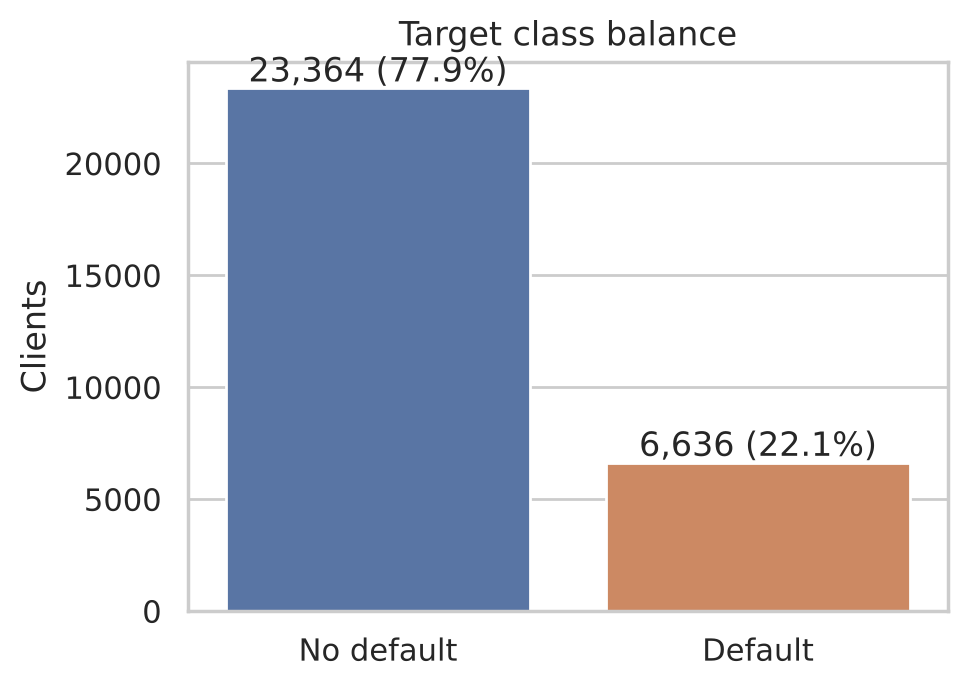

In [6]:
fig, ax = plt.subplots(figsize=(5, 3.6))
counts = df_raw["DEFAULT"].map({0: "No default", 1: "Default"}).value_counts()
sns.barplot(x=counts.index, y=counts.values, palette=["#4C72B0", "#DD8452"], ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v + 300, f"{v:,} ({v/len(df_raw):.1%})", ha="center")
ax.set_ylabel("Clients"); ax.set_xlabel(""); ax.set_title("Target class balance")
savefig("01_class_balance")

### Undocumented category codes
The UCI documentation defines EDUCATION as 1–4 and MARRIAGE as 1–3, and PAY_x as −1 (paid duly) or 1–9 (months late). The data contains codes outside those ranges.

In [7]:
for col in ["EDUCATION", "MARRIAGE", "PAY_0"]:
    print(col, dict(sorted(df_raw[col].value_counts().items())))

EDUCATION {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE {0: 54, 1: 13659, 2: 15964, 3: 323}
PAY_0 {-2: 2759, -1: 5686, 0: 14737, 1: 3688, 2: 2667, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}


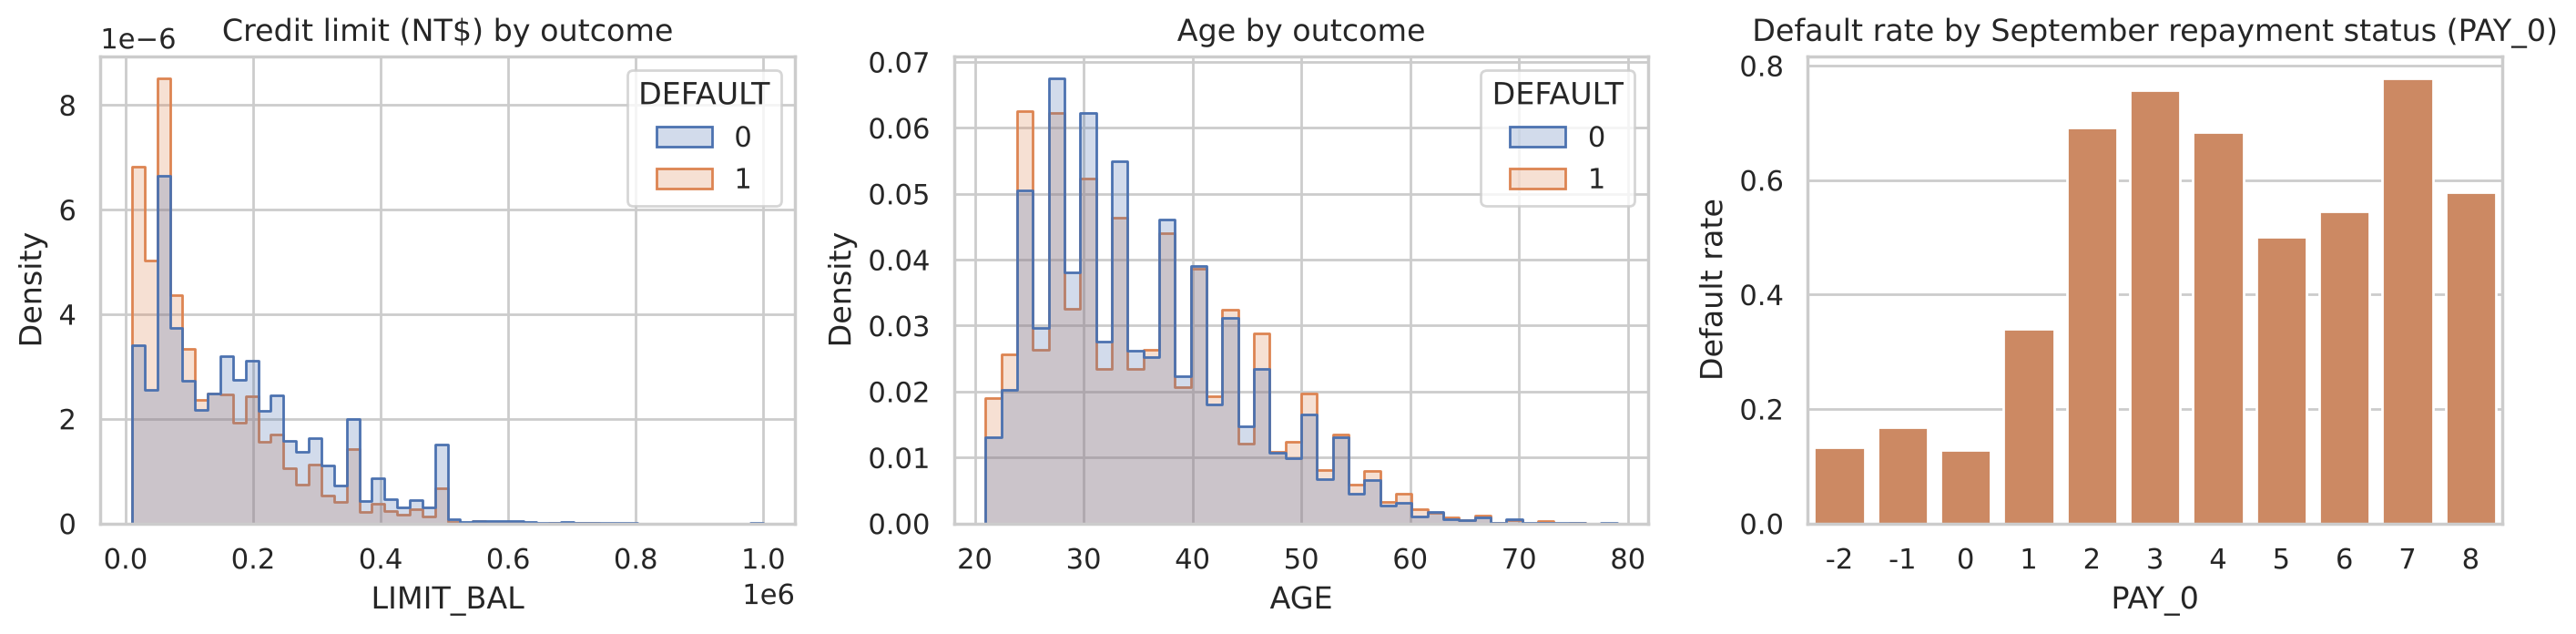

,PAY_0,mean,size
0,-2,0.132294,2759
1,-1,0.167781,5686
2,0,0.128113,14737
3,1,0.339479,3688
4,2,0.691414,2667
5,3,0.757764,322
6,4,0.684211,76
7,5,0.500000,26
8,6,0.545455,11
9,7,0.777778,9


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
sns.histplot(df_raw, x="LIMIT_BAL", hue="DEFAULT", bins=50, element="step", stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Credit limit (NT$) by outcome")
sns.histplot(df_raw, x="AGE", hue="DEFAULT", bins=40, element="step", stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("Age by outcome")
rate = df_raw.groupby("PAY_0")["DEFAULT"].agg(["mean", "size"]).reset_index()
sns.barplot(data=rate, x="PAY_0", y="mean", color="#DD8452", ax=axes[2])
axes[2].set_title("Default rate by September repayment status (PAY_0)")
axes[2].set_ylabel("Default rate")
savefig("02_key_distributions")
rate

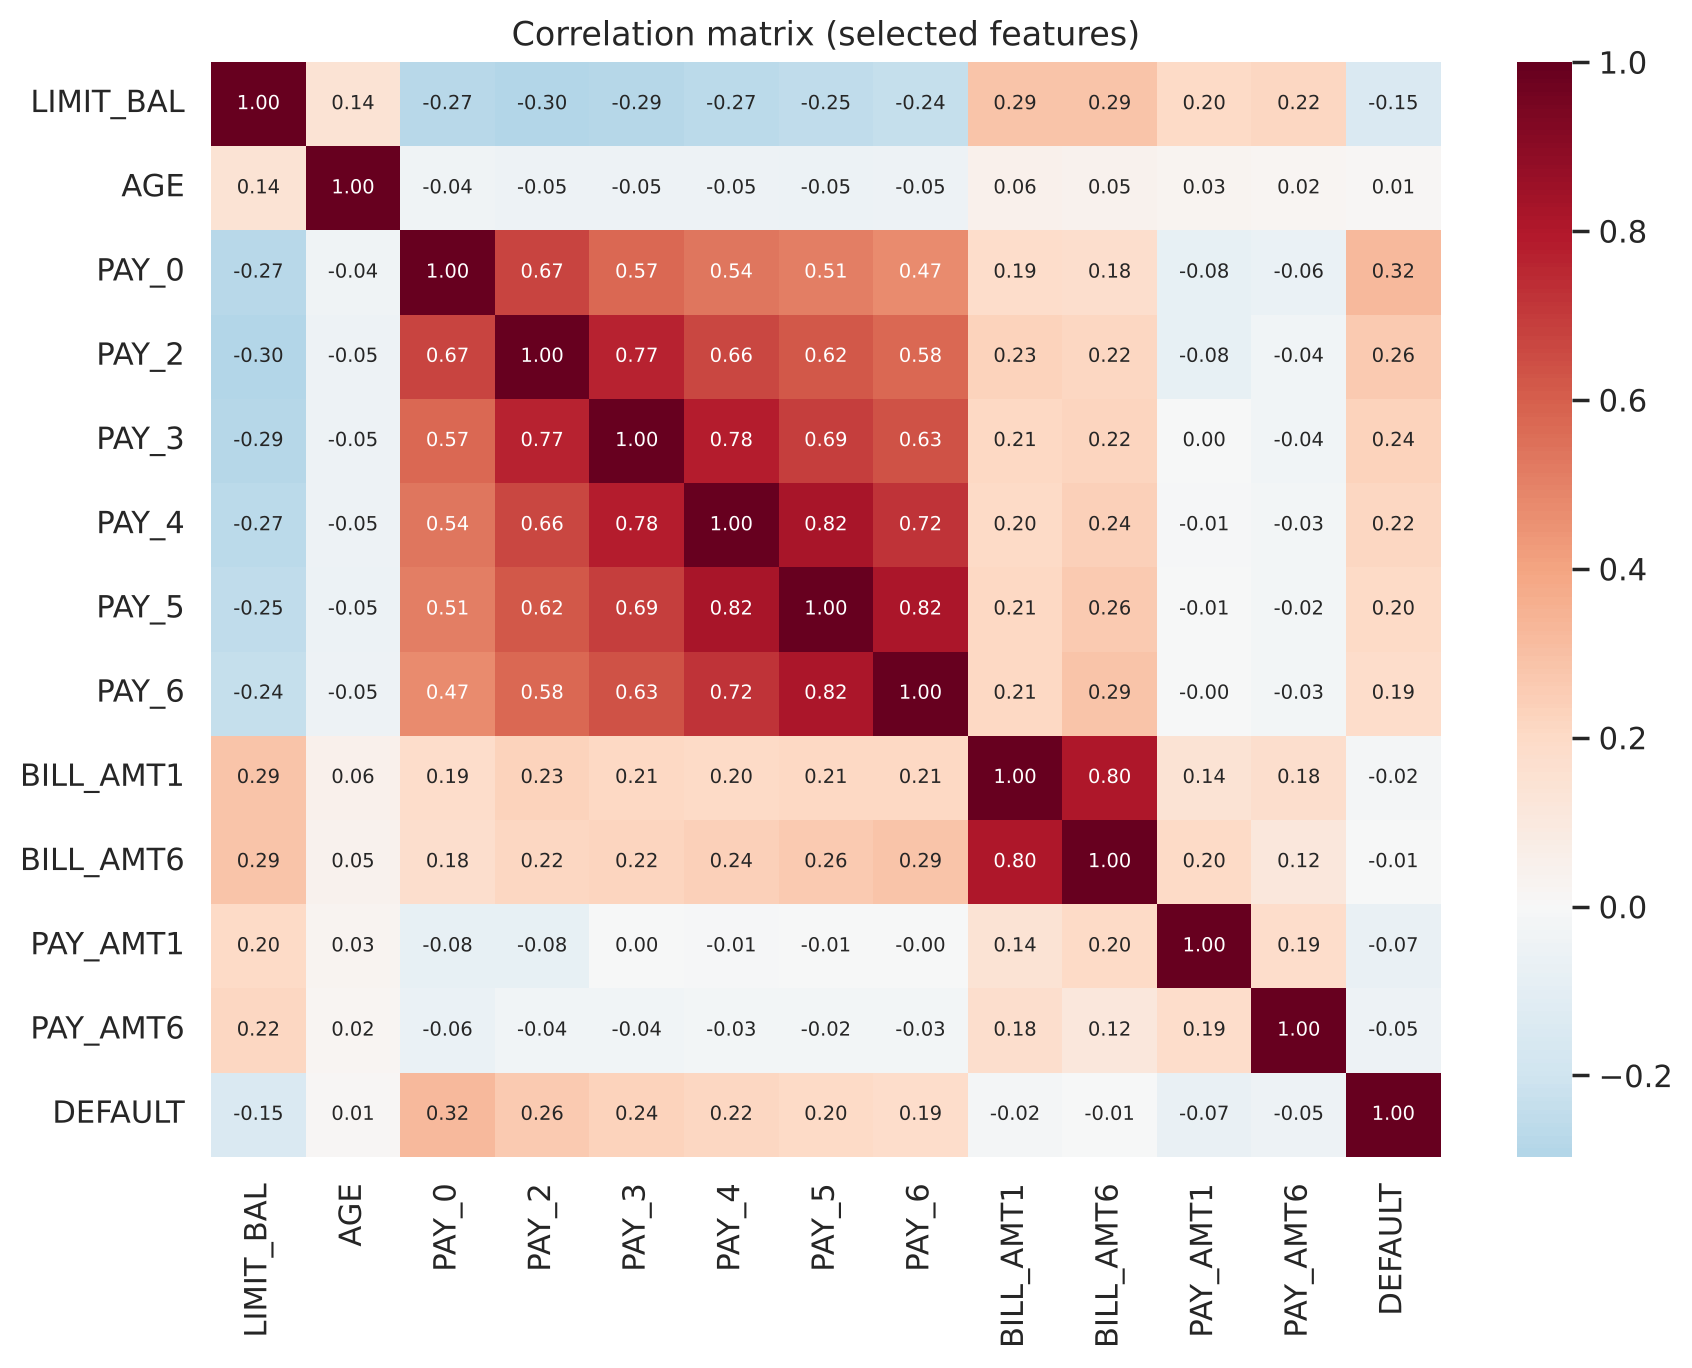

Correlation of BILL_AMT1..6 with each other (min): 0.803


PAY_0        0.325
PAY_2        0.264
PAY_3        0.235
PAY_4        0.217
PAY_5        0.204
PAY_6        0.187
AGE          0.014
BILL_AMT6   -0.005
BILL_AMT1   -0.020
PAY_AMT6    -0.053
PAY_AMT1    -0.073
LIMIT_BAL   -0.154
Name: DEFAULT, dtype: float64

In [9]:
num_cols = ["LIMIT_BAL","AGE","PAY_0","PAY_2","PAY_3","PAY_4","PAY_5","PAY_6",
            "BILL_AMT1","BILL_AMT6","PAY_AMT1","PAY_AMT6","DEFAULT"]
corr = df_raw[num_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, annot_kws={"size": 7})
plt.title("Correlation matrix (selected features)")
savefig("03_correlation")
print("Correlation of BILL_AMT1..6 with each other (min):",
      round(df_raw[[f"BILL_AMT{i}" for i in range(1,7)]].corr().values.min(), 3))
corr["DEFAULT"].drop("DEFAULT").sort_values(ascending=False).round(3)

In [10]:
# Group default rates for demographic attributes (used later in the ethics check)
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(df_raw.groupby(col)["DEFAULT"].agg(rate="mean", n="size").round(3), "\n")

      rate      n
SEX              
1    0.242  11888
2    0.208  18112 

            rate      n
EDUCATION              
0          0.000     14
1          0.192  10585
2          0.237  14030
3          0.252   4917
4          0.057    123
5          0.064    280
6          0.157     51 

           rate      n
MARRIAGE              
0         0.093     54
1         0.235  13659
2         0.209  15964
3         0.260    323 



## 4. Cleaning and preprocessing
Decisions (each justified in the report):
1. Drop `ID` (a row identifier with no predictive meaning).
2. Drop exact duplicate records (ignoring ID).
3. Collapse undocumented EDUCATION codes 0, 5, 6 into 4 ("other"); MARRIAGE 0 into 3 ("other").
4. Keep PAY_x as ordinal numbers (−2 = no consumption, −1 = paid in full, 0 = revolving credit, 1–9 = months late) — the order is meaningful.
5. Keep negative BILL_AMT values (credit balances / overpayments are legitimate) and keep large amounts (heavy right tails are real, not errors); handle skew with log transforms of engineered amounts and scaling.
6. No imputation needed: the dataset has no missing values.

In [11]:
df = df_raw.drop(columns="ID").copy()
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {n_before - len(df)} duplicate rows -> {len(df):,} rows")

df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})
print("EDUCATION:", dict(sorted(df["EDUCATION"].value_counts().items())))
print("MARRIAGE:", dict(sorted(df["MARRIAGE"].value_counts().items())))

Removed 35 duplicate rows -> 29,965 rows
EDUCATION: {1: 10563, 2: 14019, 3: 4915, 4: 468}
MARRIAGE: {1: 13643, 2: 15945, 3: 377}


### Feature engineering
Behavioural ratios a credit analyst would look at:
- **UTIL_1** – September bill / credit limit (credit utilisation)
- **AVG_UTIL** – mean utilisation over six months
- **PAY_RATIO_1** – September payment / August bill (how much of the prior bill was paid)
- **MONTHS_LATE** – number of months (of 6) with any payment delay
- **MAX_DELAY** – worst delay in the six months
- **LOG_PAY_AMT_MEAN** – log of mean monthly payment (tames skew)

In [12]:
pay_status = ["PAY_0","PAY_2","PAY_3","PAY_4","PAY_5","PAY_6"]
bills = [f"BILL_AMT{i}" for i in range(1, 7)]
pays = [f"PAY_AMT{i}" for i in range(1, 7)]

df["UTIL_1"] = df["BILL_AMT1"] / df["LIMIT_BAL"]
df["AVG_UTIL"] = df[bills].mean(axis=1) / df["LIMIT_BAL"]
df["PAY_RATIO_1"] = np.where(df["BILL_AMT2"] > 0, df["PAY_AMT1"] / df["BILL_AMT2"], 1.0)
df["PAY_RATIO_1"] = df["PAY_RATIO_1"].clip(0, 1.5)   # cap extreme overpayments
df["MONTHS_LATE"] = (df[pay_status] > 0).sum(axis=1)
df["MAX_DELAY"] = df[pay_status].max(axis=1).clip(lower=0)
df["LOG_PAY_AMT_MEAN"] = np.log1p(df[pays].mean(axis=1))

df[["UTIL_1","AVG_UTIL","PAY_RATIO_1","MONTHS_LATE","MAX_DELAY","LOG_PAY_AMT_MEAN","DEFAULT"]].corr()["DEFAULT"].round(3)

UTIL_1              0.086
AVG_UTIL            0.115
PAY_RATIO_1        -0.103
MONTHS_LATE         0.398
MAX_DELAY           0.370
LOG_PAY_AMT_MEAN   -0.155
DEFAULT             1.000
Name: DEFAULT, dtype: float64

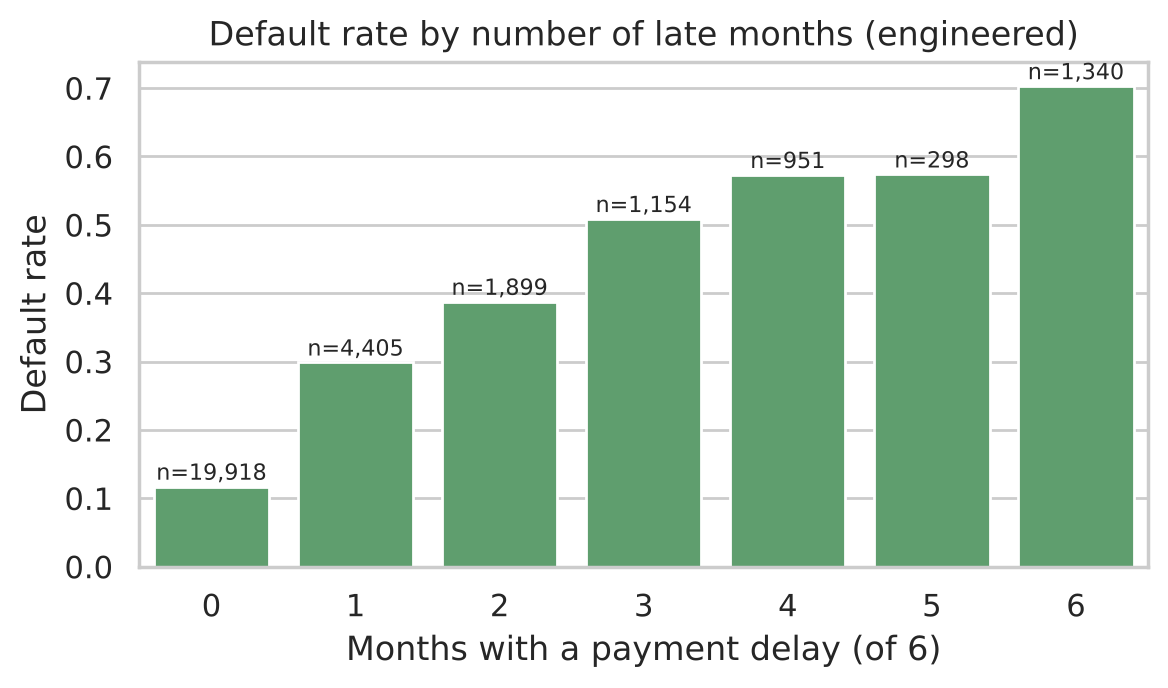

In [13]:
fig, ax = plt.subplots(figsize=(6, 3.6))
ml = df.groupby("MONTHS_LATE")["DEFAULT"].agg(["mean", "size"]).reset_index()
sns.barplot(data=ml, x="MONTHS_LATE", y="mean", color="#55A868", ax=ax)
for i, r in ml.iterrows():
    ax.text(i, r["mean"] + 0.01, f"n={int(r['size']):,}", ha="center", fontsize=8)
ax.set_title("Default rate by number of late months (engineered)")
ax.set_ylabel("Default rate"); ax.set_xlabel("Months with a payment delay (of 6)")
savefig("04_months_late")

### Encoding, scaling, and train/test split
- Nominal features (SEX, EDUCATION, MARRIAGE) are one-hot encoded (`drop="first"`).
- Numeric features are standardised with `StandardScaler`.
- **Leakage control:** the scaler and encoder sit inside a scikit-learn `Pipeline`, so they are fit on training folds only. (The starter hint scales the whole dataset before splitting; we deliberately split first.)
- **Stratified 75/25 split** keeps the ~22% default rate equal in both sets.

In [14]:
TARGET = "DEFAULT"
cat_features = ["SEX", "EDUCATION", "MARRIAGE"]
num_features = [c for c in df.columns if c not in cat_features + [TARGET]]

X = df.drop(columns=TARGET)
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "default rate", round(y_train.mean(), 4))
print("Test: ", X_test.shape, "default rate", round(y_test.mean(), 4))
print("Numeric features:", len(num_features), "| Categorical:", len(cat_features))

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_features),
])

Train: (22473, 29) default rate 0.2212
Test:  (7492, 29) default rate 0.2213
Numeric features: 26 | Categorical: 3


## 5. Initial model development
Three models, all evaluated on the same held-out test set:
- **Dummy (majority class)** — the floor any model must beat.
- **Logistic Regression** — interpretable linear baseline; `class_weight="balanced"` to counter the 78/22 imbalance.
- **Random Forest** — non-linear ensemble that can capture interactions (e.g. utilisation × delay).

Because only ~22% of clients default, **accuracy is misleading** (always predicting "no default" scores ~78%). We report ROC-AUC, recall and F1 for the default class.

In [15]:
models = {
    "Dummy (majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample",
                                            n_jobs=-1, random_state=RANDOM_STATE),
}

results, fitted = [], {}
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    fitted[name] = pipe
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (default)": precision_score(y_test, pred, zero_division=0),
        "Recall (default)": recall_score(y_test, pred),
        "F1 (default)": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "PR-AUC": average_precision_score(y_test, proba),
    })
results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

,Accuracy,Precision (default),Recall (default),F1 (default),ROC-AUC,PR-AUC
Model,,,,,,
Dummy (majority),0.779,0.000,0.000,0.000,0.500,0.221
Logistic Regression,0.739,0.438,0.630,0.516,0.764,0.522
Random Forest,0.798,0.548,0.506,0.526,0.776,0.554


In [16]:
for name in ["Logistic Regression", "Random Forest"]:
    print(f"=== {name} ===")
    print(classification_report(y_test, fitted[name].predict(X_test), target_names=["No default", "Default"], digits=3))

=== Logistic Regression ===
              precision    recall  f1-score   support

  No default      0.880     0.770     0.821      5834
     Default      0.438     0.630     0.516      1658

    accuracy                          0.739      7492
   macro avg      0.659     0.700     0.669      7492
weighted avg      0.782     0.739     0.754      7492

=== Random Forest ===


              precision    recall  f1-score   support

  No default      0.863     0.882     0.872      5834
     Default      0.548     0.506     0.526      1658

    accuracy                          0.798      7492
   macro avg      0.705     0.694     0.699      7492
weighted avg      0.793     0.798     0.795      7492



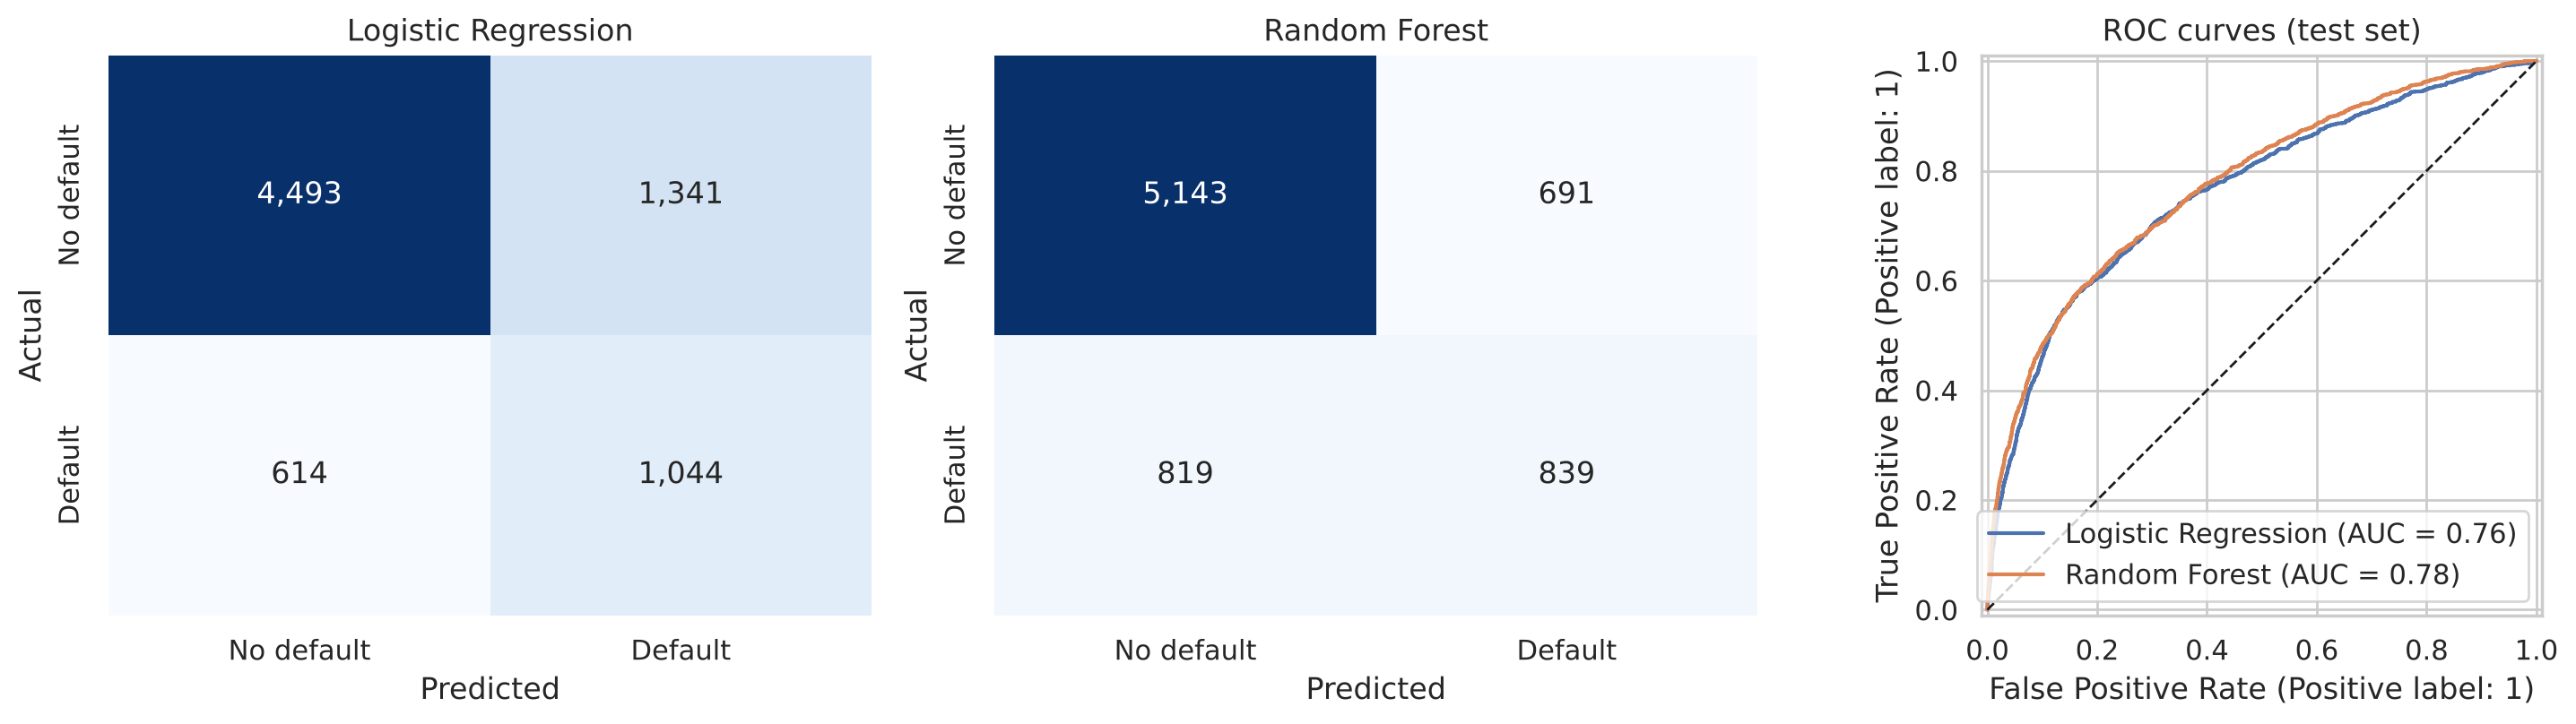

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, name in zip(axes[:2], ["Logistic Regression", "Random Forest"]):
    cm = confusion_matrix(y_test, fitted[name].predict(X_test))
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No default", "Default"], yticklabels=["No default", "Default"])
    ax.set_title(f"{name}"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
for name in ["Logistic Regression", "Random Forest"]:
    RocCurveDisplay.from_estimator(fitted[name], X_test, y_test, ax=axes[2], name=name)
axes[2].plot([0, 1], [0, 1], "k--", lw=1)
axes[2].set_title("ROC curves (test set)")
savefig("05_confusion_roc")

### 5-fold cross-validation (training set) — checks the test result isn't a lucky split

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name in ["Logistic Regression", "Random Forest"]:
    scores = cross_val_score(Pipeline([("prep", preprocess), ("clf", models[name])]),
                             X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    print(f"{name}: ROC-AUC {scores.mean():.3f} ± {scores.std():.3f}")

Logistic Regression: ROC-AUC 0.769 ± 0.009


Random Forest: ROC-AUC 0.782 ± 0.008


### First-pass hyperparameter tuning (Random Forest)

In [19]:
param_grid = {
    "clf__n_estimators": [200, 400],
    "clf__max_depth": [8, 12, None],
    "clf__min_samples_leaf": [5, 20],
}
grid = GridSearchCV(Pipeline([("prep", preprocess), ("clf", models["Random Forest"])]),
                    param_grid, cv=3, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)
print("Best params:", grid.best_params_)
print("Best CV ROC-AUC:", round(grid.best_score_, 3))
best_rf = grid.best_estimator_
proba_best = best_rf.predict_proba(X_test)[:, 1]
pred_best = best_rf.predict(X_test)
print("Tuned RF test ROC-AUC:", round(roc_auc_score(y_test, proba_best), 3),
      "| recall:", round(recall_score(y_test, pred_best), 3),
      "| precision:", round(precision_score(y_test, pred_best), 3),
      "| F1:", round(f1_score(y_test, pred_best), 3),
      "| accuracy:", round(accuracy_score(y_test, pred_best), 3),
      "| PR-AUC:", round(average_precision_score(y_test, proba_best), 3))

Best params: {'clf__max_depth': 12, 'clf__min_samples_leaf': 20, 'clf__n_estimators': 400}
Best CV ROC-AUC: 0.787


Tuned RF test ROC-AUC: 0.781 | recall: 0.598 | precision: 0.49 | F1: 0.539 | accuracy: 0.773 | PR-AUC: 0.561


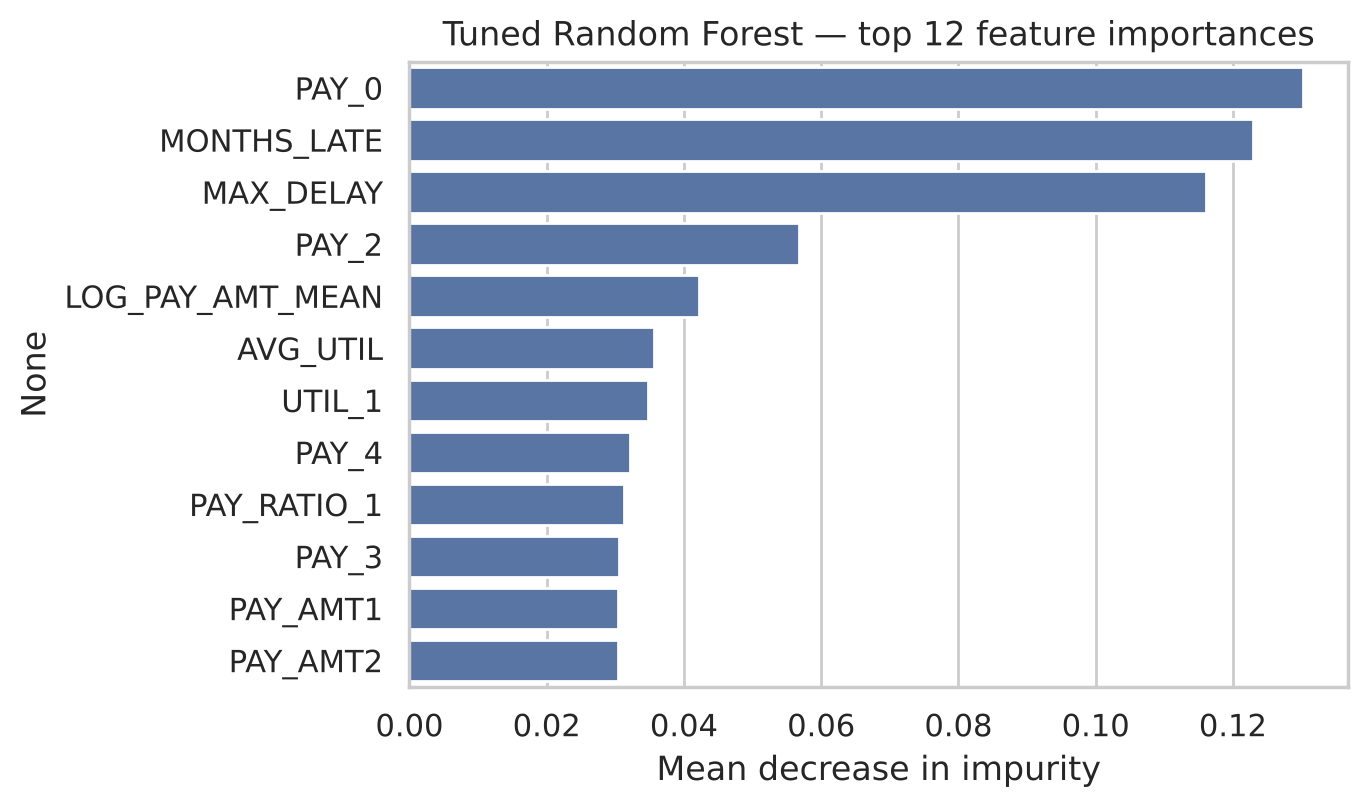

PAY_0               0.130
MONTHS_LATE         0.123
MAX_DELAY           0.116
PAY_2               0.057
LOG_PAY_AMT_MEAN    0.042
AVG_UTIL            0.036
UTIL_1              0.035
PAY_4               0.032
PAY_RATIO_1         0.031
PAY_3               0.031
PAY_AMT1            0.030
PAY_AMT2            0.030
dtype: float64

In [20]:
feat_names = best_rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(best_rf.named_steps["clf"].feature_importances_, index=feat_names)
imp.index = imp.index.str.replace("num__", "").str.replace("cat__", "")
top = imp.sort_values(ascending=False).head(12)
plt.figure(figsize=(7, 4.2))
sns.barplot(x=top.values, y=top.index, color="#4C72B0")
plt.title("Tuned Random Forest — top 12 feature importances"); plt.xlabel("Mean decrease in impurity")
savefig("06_feature_importance")
top.round(3)

In [21]:
lr = fitted["Logistic Regression"]
coefs = pd.Series(lr.named_steps["clf"].coef_[0], index=lr.named_steps["prep"].get_feature_names_out())
coefs.index = coefs.index.str.replace("num__", "").str.replace("cat__", "")
coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10).round(3)

EDUCATION_4        -0.859
MONTHS_LATE         0.517
MAX_DELAY           0.378
BILL_AMT2           0.365
LOG_PAY_AMT_MEAN   -0.209
PAY_0               0.202
LIMIT_BAL          -0.202
PAY_AMT1           -0.181
AVG_UTIL            0.171
MARRIAGE_2         -0.161
dtype: float64

## 6. Ethical considerations — first fairness check
- **Potential bias:** SEX, MARRIAGE, EDUCATION and AGE are legally protected or sensitive attributes in many lending regimes (e.g. US ECOA). Even if removed, proxies (credit limit, education) may carry the same signal.
- **Across groups:** below we compare recall (share of real defaulters caught) and flag rate by SEX and age band for the tuned model.
- **Interpretability:** Logistic Regression coefficients are directly explainable; Random Forest needs post-hoc tools (permutation importance / SHAP) — planned for the next deliverable.
- **Data protection:** the data is anonymised (no names/IDs); a production system would need consent, retention limits and access controls.

In [22]:
audit = X_test[["SEX", "AGE"]].copy()
audit["y"] = y_test.values; audit["pred"] = pred_best
audit["SEX"] = audit["SEX"].map({1: "Male", 2: "Female"})
audit["AGE_BAND"] = pd.cut(audit["AGE"], [20, 30, 40, 50, 80], labels=["21-30", "31-40", "41-50", "51+"])

def group_metrics(g):
    return pd.Series({"n": len(g), "actual_default_rate": g["y"].mean(), "flag_rate": g["pred"].mean(),
                      "recall": recall_score(g["y"], g["pred"]), "precision": precision_score(g["y"], g["pred"], zero_division=0)})

print(audit.groupby("SEX").apply(group_metrics).round(3), "\n")
print(audit.groupby("AGE_BAND").apply(group_metrics).round(3))

             n  actual_default_rate  flag_rate  recall  precision
SEX                                                              
Female  4554.0                0.208      0.252   0.603      0.497
Male    2938.0                0.242      0.298   0.592      0.481 

               n  actual_default_rate  flag_rate  recall  precision
AGE_BAND                                                           
21-30     2737.0                0.222      0.288   0.609      0.469
31-40     2627.0                0.203      0.247   0.572      0.469
41-50     1532.0                0.235      0.261   0.600      0.540
51+        596.0                0.263      0.309   0.643      0.549


## 7. Summary and next steps
- Repayment history (PAY_0 and the engineered delay features) dominates; demographic features contribute little.
- Both models clearly beat the majority-class baseline on ROC-AUC; the tuned Random Forest is the strongest initial model.
- **Next deliverable:** threshold tuning against a lender cost matrix, gradient boosting (e.g. HistGradientBoosting), SHAP explanations, and a fuller fairness evaluation (equal-opportunity gap, model without protected attributes).